<a href="https://colab.research.google.com/github/arunreghunath25b-afk/Predicting_the_sex_of_laysan/blob/main/Laysan_Sex_Prediction_Arun.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression


In [4]:
data=pd.read_csv("/content/drive/MyDrive/DSA/Case study/train.csv")

In [6]:
data.head()

,id,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,0J4_2016,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,208.4,2.38
1,A68_2016,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,204.4,2.14
2,E55_2015,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,210.4,2.50
3,7C7_2016,M,182.25,113.17,84.13,52.26,32.08,26.07,91.74,52.6,98.9,107.6,215.2,2.83
4,2C0_2018,H,173.70,105.19,80.37,49.20,34.00,27.12,87.77,50.8,94.5,103.7,207.4,2.73


In [8]:
data.isnull().sum()

,0
id,0
sexo,0
longitudCraneo,0
longitudPico,0
longitudNarina,0
anchoCraneo,0
altoPico,0
anchoPico,0
tarso,0
longAlaCerrada,0


In [12]:
data.duplicated().sum()

np.int64(0)

In [14]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                94 non-null     object 
 1   sexo              94 non-null     object 
 2   longitudCraneo    94 non-null     float64
 3   longitudPico      94 non-null     float64
 4   longitudNarina    94 non-null     float64
 5   anchoCraneo       94 non-null     float64
 6   altoPico          94 non-null     float64
 7   anchoPico         94 non-null     float64
 8   tarso             94 non-null     float64
 9   longAlaCerrada    94 non-null     float64
 10  longAlaAbierta    94 non-null     float64
 11  mediaEnvergadura  94 non-null     float64
 12  envergadura       94 non-null     float64
 13  peso              93 non-null     float64
dtypes: float64(12), object(2)
memory usage: 10.4+ KB


In [16]:
data.select_dtypes(include='number').columns


Index(['longitudCraneo', 'longitudPico', 'longitudNarina', 'anchoCraneo',
       'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada', 'longAlaAbierta',
       'mediaEnvergadura', 'envergadura', 'peso'],
      dtype='object')

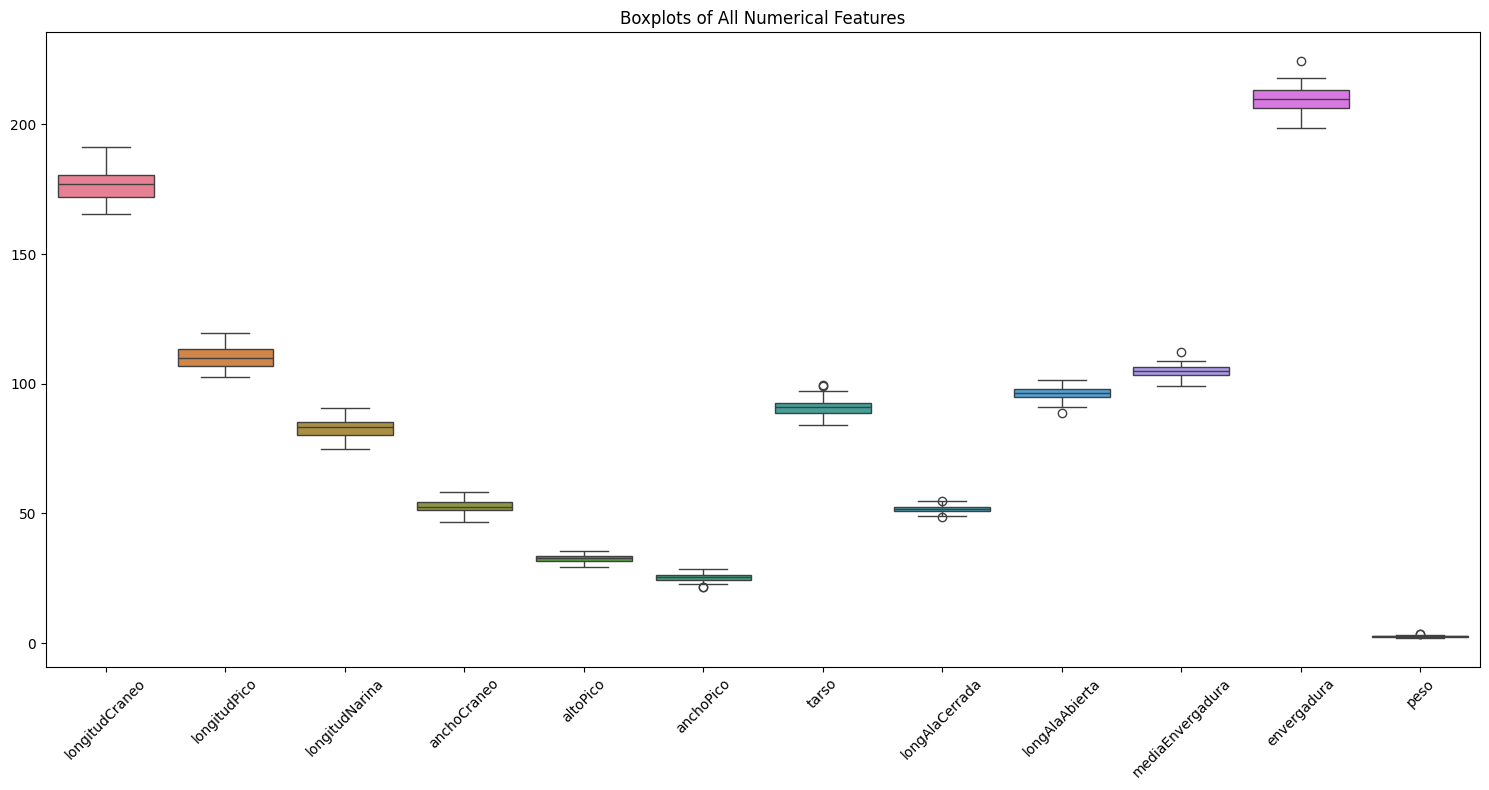

In [23]:
num_cols = data.select_dtypes(include="number").columns.drop(
    "id", errors="ignore"
)

plt.figure(figsize=(15, 8))
sns.boxplot(data=data[num_cols])
plt.title("Boxplots of All Numerical Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

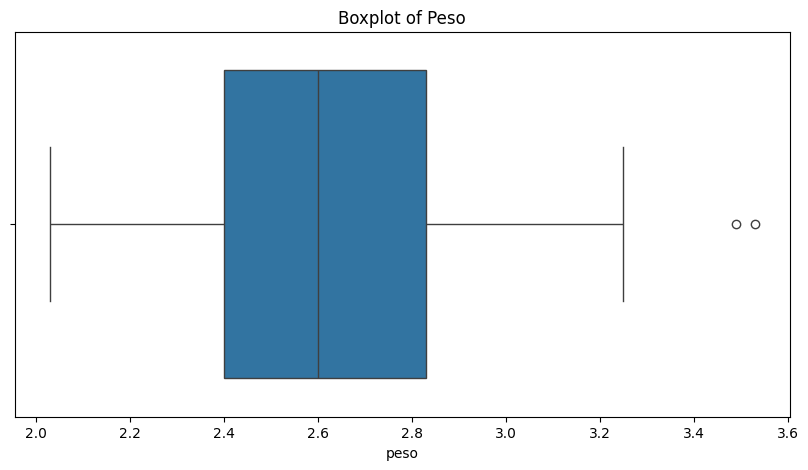

In [18]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=data["peso"])
plt.title("Boxplot of Peso")
plt.show()

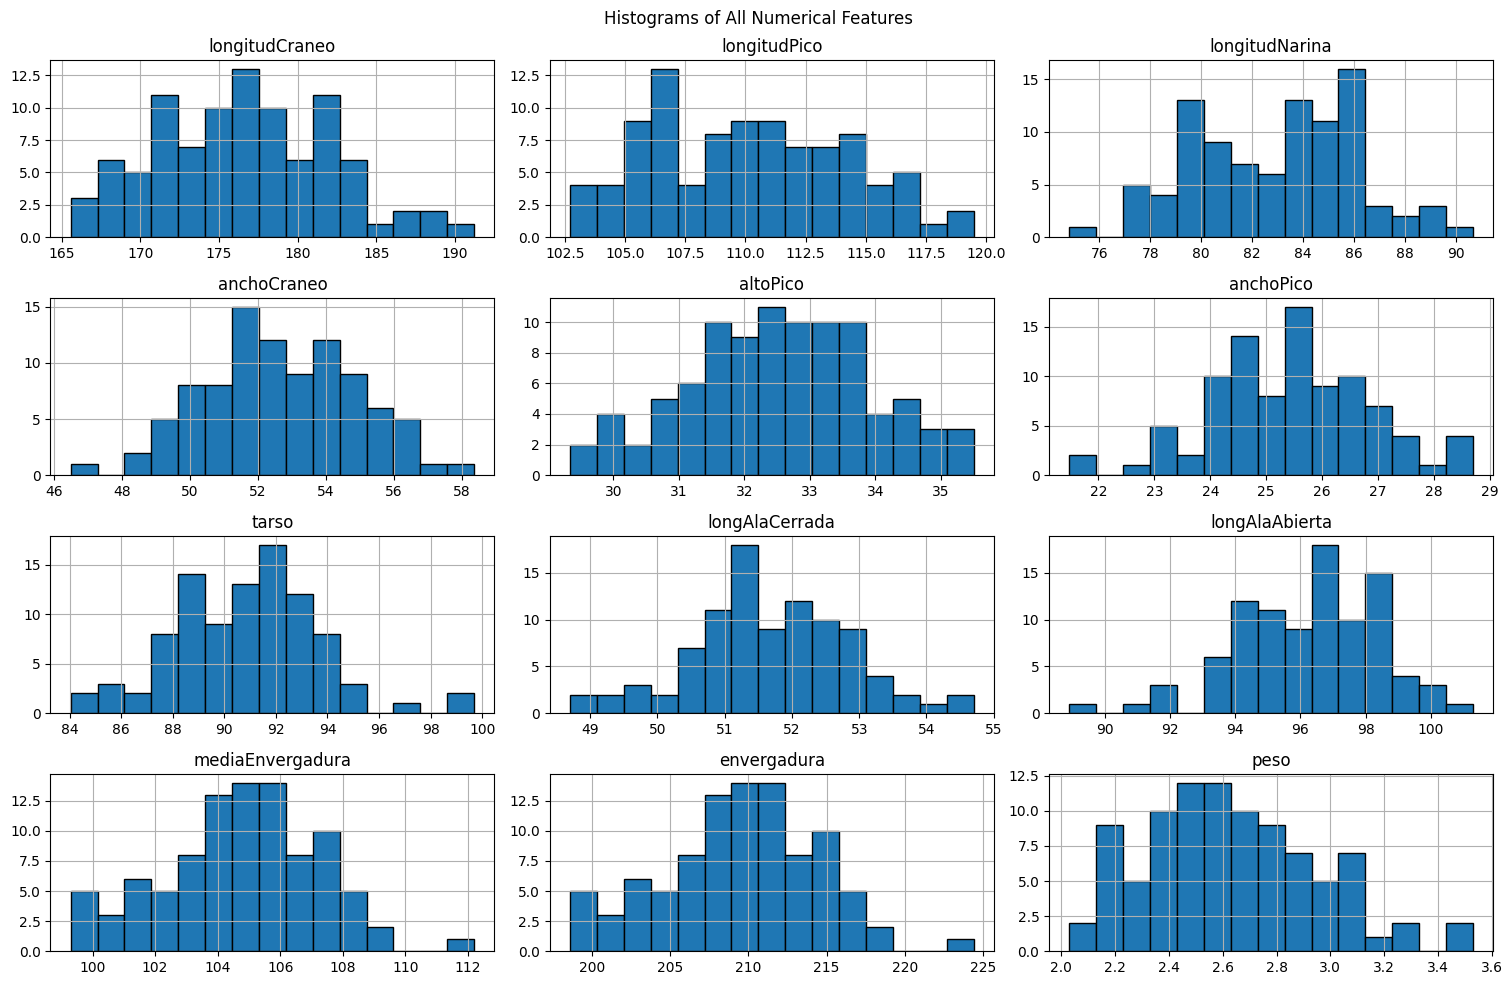

In [24]:
data[num_cols].hist(figsize=(15, 10), bins=15, edgecolor="black")
plt.suptitle("Histograms of All Numerical Features")
plt.tight_layout()
plt.show()

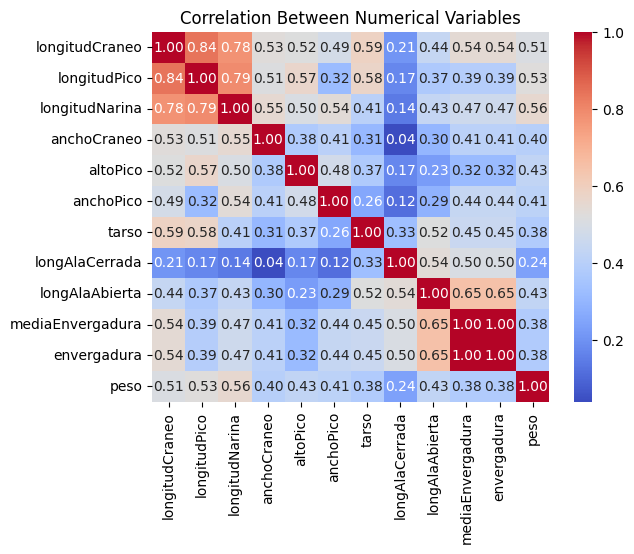

In [20]:
numeric_data = data.select_dtypes(include='number').drop(
    columns=['id'], errors='ignore'
)

correlation = numeric_data.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Numerical Variables')
plt.show()

In [21]:
import numpy as np

corr = numeric_data.corr()

# Keep only the upper triangle, excluding the diagonal
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

# Sort correlations from strongest to weakest by absolute value
strongest = upper.abs().stack().sort_values(ascending=False)

print(strongest.head(10))

mediaEnvergadura  envergadura         1.000000
longitudCraneo    longitudPico        0.840354
longitudPico      longitudNarina      0.793306
longitudCraneo    longitudNarina      0.776635
longAlaAbierta    envergadura         0.647892
                  mediaEnvergadura    0.647892
longitudCraneo    tarso               0.586269
longitudPico      tarso               0.575282
                  altoPico            0.568365
longitudNarina    peso                0.556491
dtype: float64


In [26]:
print(data.select_dtypes(include="object").nunique())

id      94
sexo     2
dtype: int64


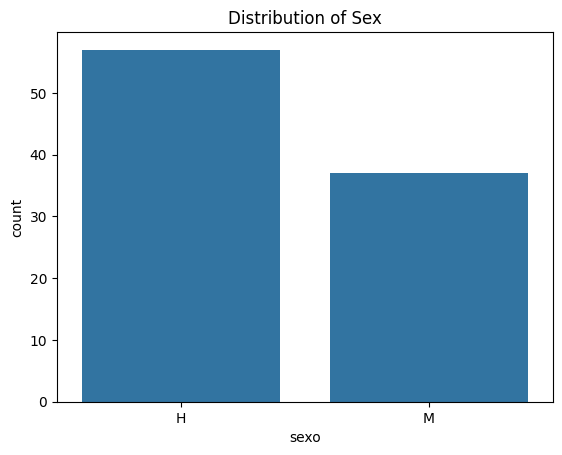

In [28]:
sns.countplot(data=data, x="sexo")
plt.title("Distribution of Sex")
plt.show()

In [30]:
data["peso"] = data["peso"].fillna(data["peso"].median())

In [32]:
data.isnull().sum()

,0
id,0
sexo,0
longitudCraneo,0
longitudPico,0
longitudNarina,0
anchoCraneo,0
altoPico,0
anchoPico,0
tarso,0
longAlaCerrada,0


In [34]:
num_cols = data.select_dtypes(include="number").columns.drop("id", errors="ignore")

for col in num_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((data[col] < lower) | (data[col] > upper)).sum()

    print(f"{col}: {count} outliers")

longitudCraneo: 0 outliers
longitudPico: 0 outliers
longitudNarina: 0 outliers
anchoCraneo: 0 outliers
altoPico: 0 outliers
anchoPico: 2 outliers
tarso: 2 outliers
longAlaCerrada: 2 outliers
longAlaAbierta: 1 outliers
mediaEnvergadura: 1 outliers
envergadura: 1 outliers
peso: 2 outliers


In [36]:
X = data.drop(columns=["id", "sexo"])
y = data["sexo"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (94, 12)
Target shape: (94,)


In [38]:
print(y.value_counts())

sexo
H    57
M    37
Name: count, dtype: int64


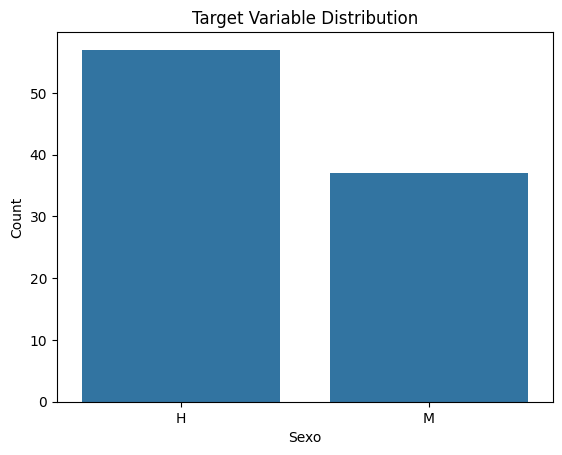

In [40]:
sns.countplot(data=data, x="sexo")
plt.title("Target Variable Distribution")
plt.xlabel("Sexo")
plt.ylabel("Count")
plt.show()

In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (75, 12)
X_test: (19, 12)
y_train: (75,)
y_test: (19,)


In [44]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (75, 12)
Testing shape: (19, 12)


In [46]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Predictions:", y_pred)

Predictions: ['M' 'H' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'H' 'H' 'H' 'M' 'M' 'H' 'M' 'H'
 'H']


In [48]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8947368421052632

Classification Report:
              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



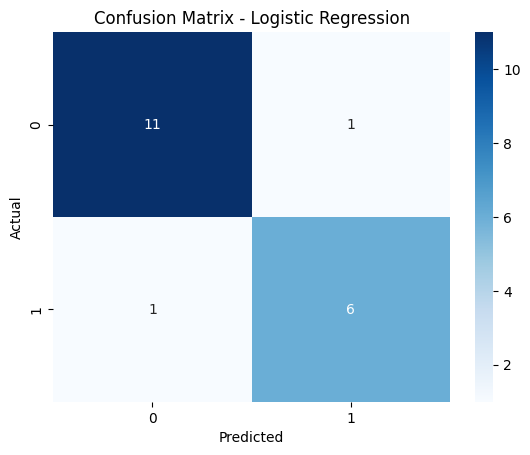

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [52]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 0.8947368421052632

Classification Report:
              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



In [54]:
from sklearn.svm import SVC

svm = SVC(kernel="rbf")

svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.7894736842105263

Classification Report:
              precision    recall  f1-score   support

           H       0.79      0.92      0.85        12
           M       0.80      0.57      0.67         7

    accuracy                           0.79        19
   macro avg       0.79      0.74      0.76        19
weighted avg       0.79      0.79      0.78        19



In [56]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.8421052631578947

Classification Report:
              precision    recall  f1-score   support

           H       0.85      0.92      0.88        12
           M       0.83      0.71      0.77         7

    accuracy                           0.84        19
   macro avg       0.84      0.82      0.82        19
weighted avg       0.84      0.84      0.84        19



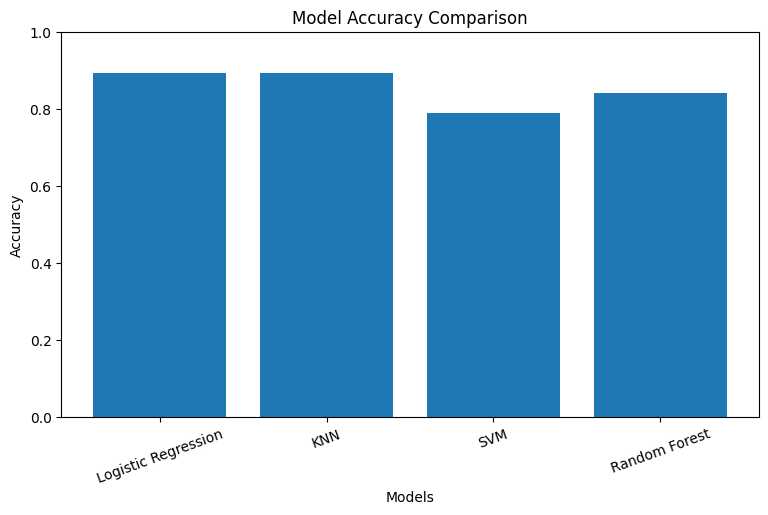

In [58]:
models = ["Logistic Regression", "KNN", "SVM", "Random Forest"]

accuracies = [
    accuracy_score(y_test, y_pred),
    accuracy_score(y_test, y_pred_knn),
    accuracy_score(y_test, y_pred_svm),
    accuracy_score(y_test, y_pred_rf)
]

plt.figure(figsize=(9, 5))
plt.bar(models, accuracies)
plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

In [60]:
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf"),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

for name, model in models.items():
    scores = cross_val_score(
        model, X_train_scaled, y_train, cv=5, scoring="accuracy"
    )
    print(name)
    print("CV Accuracy:", scores.mean().round(3))
    print("Standard Deviation:", scores.std().round(3))
    print()

Logistic Regression
CV Accuracy: 0.933
Standard Deviation: 0.042

KNN
CV Accuracy: 0.893
Standard Deviation: 0.08

SVM
CV Accuracy: 0.893
Standard Deviation: 0.068

Random Forest
CV Accuracy: 0.907
Standard Deviation: 0.053



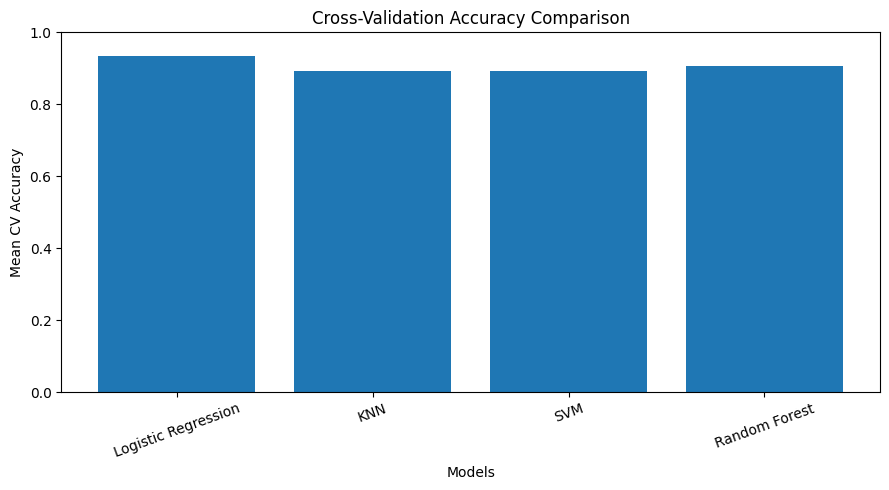

In [62]:
cv_models = [
    "Logistic Regression",
    "KNN",
    "SVM",
    "Random Forest"
]

cv_accuracies = [0.933, 0.893, 0.893, 0.907]

plt.figure(figsize=(9, 5))
plt.bar(cv_models, cv_accuracies)
plt.title("Cross-Validation Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Mean CV Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [64]:
from sklearn.metrics import f1_score

model_names = [
    "Logistic Regression",
    "KNN",
    "SVM",
    "Random Forest"
]

predictions = [
    y_pred,
    y_pred_knn,
    y_pred_svm,
    y_pred_rf
]

for name, pred in zip(model_names, predictions):
    print(name)
    print("Macro F1:", round(
        f1_score(y_test, pred, average="macro"), 4
    ))
    print("Weighted F1:", round(
        f1_score(y_test, pred, average="weighted"), 4
    ))
    print()

Logistic Regression
Macro F1: 0.8869
Weighted F1: 0.8947

KNN
Macro F1: 0.8869
Weighted F1: 0.8947

SVM
Macro F1: 0.7564
Weighted F1: 0.78

Random Forest
Macro F1: 0.8246
Weighted F1: 0.8392



In [66]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "KNN": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "SVM": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC(kernel="rbf")
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=100, random_state=42)
    )
}

for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="f1_macro"
    )
    print(name)
    print("Mean Macro F1:", round(scores.mean(), 4))
    print("Standard Deviation:", round(scores.std(), 4))
    print()

Logistic Regression
Mean Macro F1: 0.9165
Standard Deviation: 0.0519

KNN
Mean Macro F1: 0.9047
Standard Deviation: 0.0336

SVM
Mean Macro F1: 0.9183
Standard Deviation: 0.0511

Random Forest
Mean Macro F1: 0.8492
Standard Deviation: 0.0265



In [68]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf"))
])

final_model.fit(X_train, y_train)

y_pred_final = final_model.predict(X_test)

print("Macro F1:", f1_score(y_test, y_pred_final, average="macro"))
print("Weighted F1:", f1_score(y_test, y_pred_final, average="weighted"))

Macro F1: 0.7564102564102564
Weighted F1: 0.7800269905533063


In [70]:
from sklearn.metrics import f1_score, classification_report

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

print("Macro F1:", f1_score(y_test, y_pred_lr, average="macro"))
print("Weighted F1:", f1_score(y_test, y_pred_lr, average="weighted"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Macro F1: 0.8869047619047619
Weighted F1: 0.8947368421052632

Classification Report:
              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



In [72]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

final_model.fit(X_train, y_train)

joblib.dump(final_model, "albatross_sex_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [73]:
test_df = pd.read_csv("/content/drive/MyDrive/DSA/Case study/test.csv")

test_ids = test_df["id"]

X_competition = test_df.drop(columns=["id", "sexo"], errors="ignore")

predictions = final_model.predict(X_competition)

submission = pd.DataFrame({
    "id": test_ids,
    "sexo": predictions
})

submission.to_csv("/content/drive/MyDrive/DSA/Case study/sample_submission.csv", index=False)

print(submission.head())
print("Submission file created successfully!")

         id sexo
0  A70_2018    M
1  5C9_2018    H
2  5E1_2018    M
3  C58_2018    M
4  5E2_2018    M
Submission file created successfully!
